<a href="https://colab.research.google.com/github/lamia-khd/react-router/blob/master/imputation_and_imbalance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI", "DiabetesPedigreeFunction","Age","Outcome"]

try:
    df = pd.read_csv(URL, header=None, names=COLS)
except Exception as e:
    from sklearn.datasets import fetch_openml
    d = fetch_openml(data_id=37, as_frame=True, parser="auto").frame
    d.columns = COLS
    d["Outcome"] = (d["Outcome"].astype(str).str.contains("pos|positive")).astype(int)
    df = d

print(df.shape)
print(df.head())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


Zeros per column (before):
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64 

% missing:
 Insulin          48.7
SkinThickness    29.6
BloodPressure     4.6
BMI               1.4
Glucose           0.7
dtype: float64


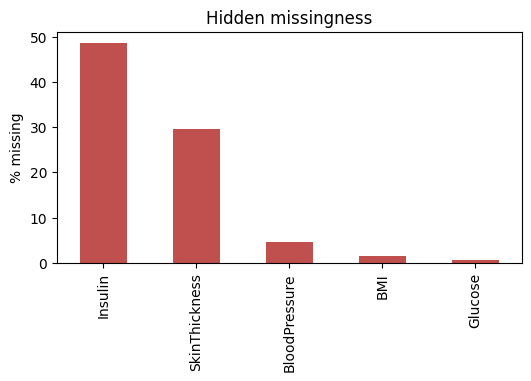


Complete rows: 392 of 768
Class balance:
 Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


In [4]:
import numpy as np
import matplotlib.pyplot as plt
ZERO_AS_MISSING = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print("Zeros per column (before):\n", (df[ZERO_AS_MISSING] == 0).sum(), "\n")
df[ZERO_AS_MISSING] = df[ZERO_AS_MISSING].replace(0, np.nan)
miss = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("% missing:\n", miss[miss > 0])
ax = miss[miss > 0].plot.bar(color="#c0504d", figsize=(6,3));
ax.set_ylabel("% missing"); ax.set_title("Hidden missingness")
plt.show()
print("\nComplete rows:", len(df.dropna()), "of", len(df))
print("Class balance:\n", df.Outcome.value_counts(normalize=True).round(3))